In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn xgboost

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

df = X.copy()
df["MedHouseVal"] = y

print(df.head())
print(df.shape)
print(df.isnull().sum())
print(df.describe())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
(20640, 9)
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [4]:
models = {

    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Neural Network": Pipeline([
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            max_iter=300,
            early_stopping=True,
            random_state=42
        ))
    ]),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=5
        ))
    ])
}

In [5]:
results = []
predictions = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Display comparison
results_df = pd.DataFrame(results)

print(results_df.round(4))

           Algorithm     MAE     MSE    RMSE  R2 Score
0  Linear Regression  0.5332  0.5559  0.7456    0.5758
1      Decision Tree  0.4332  0.4155  0.6446    0.6829
2      Random Forest  0.3275  0.2554  0.5053    0.8051
3     Neural Network  0.3533  0.2745  0.5239    0.7905
4            XGBoost  0.3550  0.2726  0.5221    0.7920
5                KNN  0.4462  0.4324  0.6576    0.6700


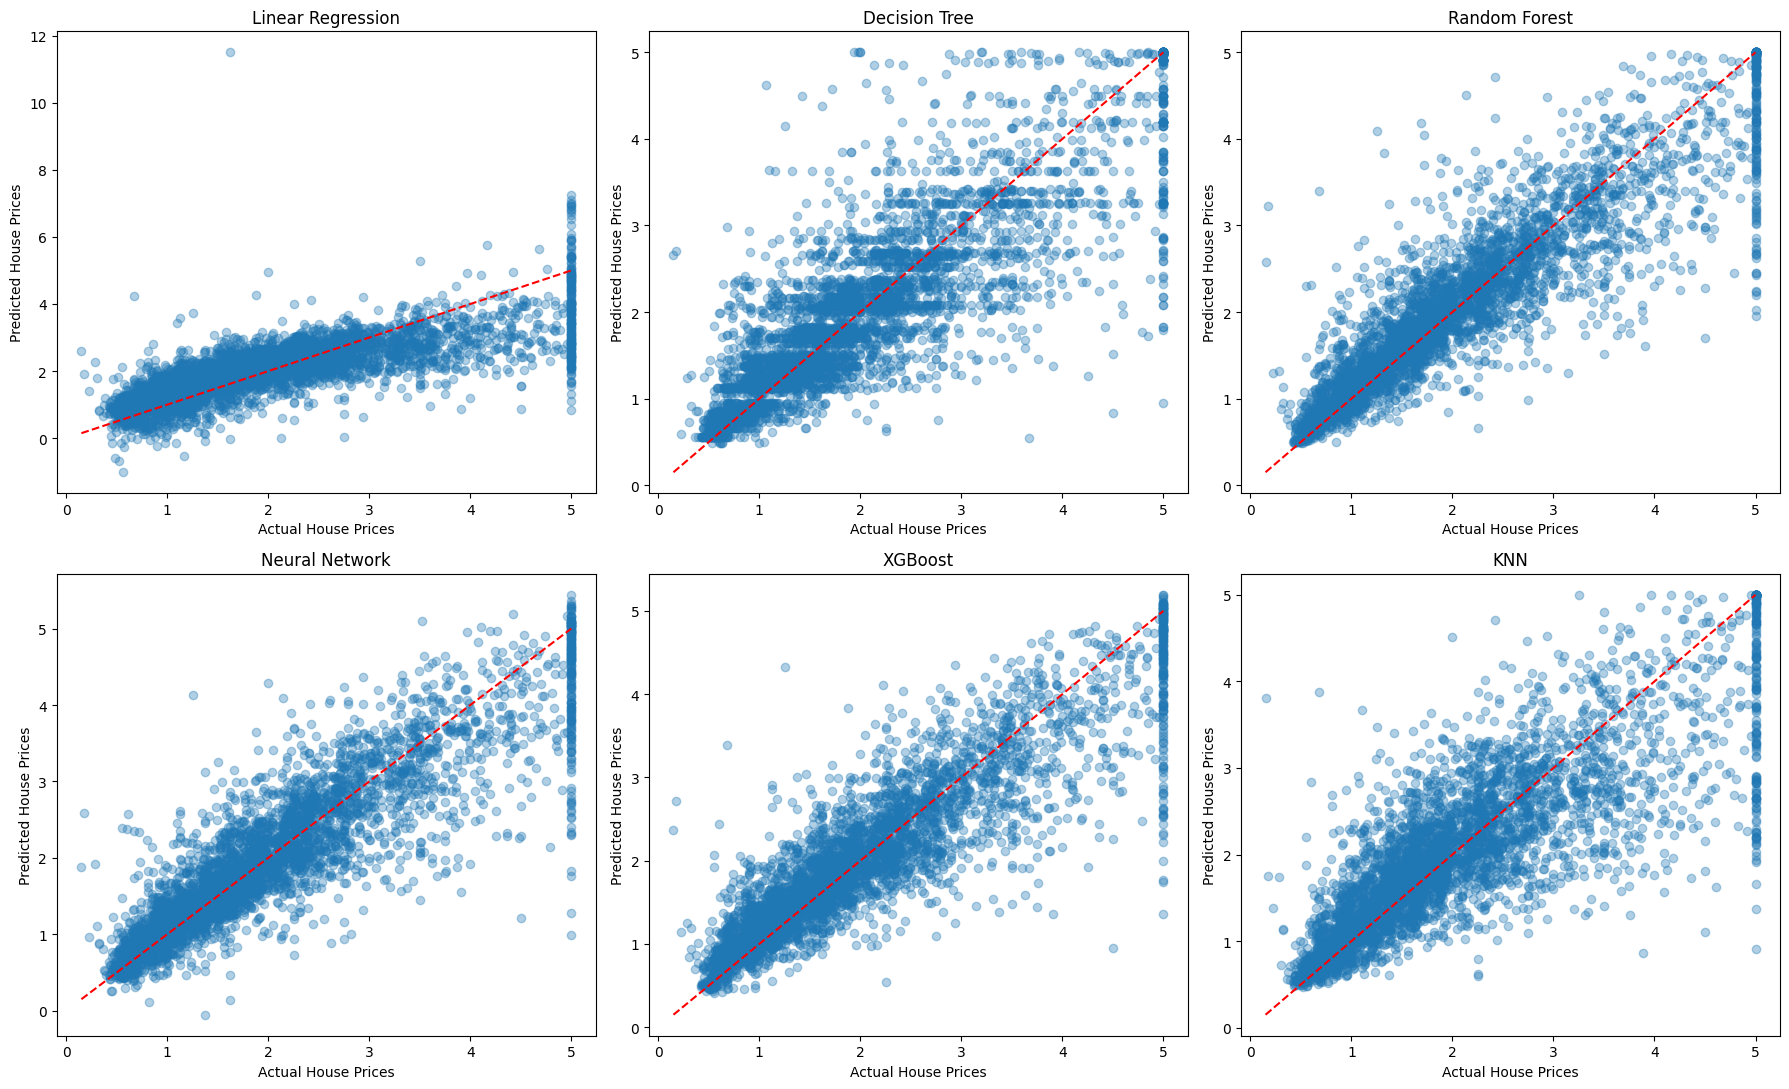

In [6]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 11)
)

axes = axes.flatten()

for ax, (name, y_pred) in zip(
    axes, predictions.items()
):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.35
    )

    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Prices")
    ax.set_ylabel("Predicted House Prices")

plt.tight_layout()
plt.show()

In [7]:
best_model = results_df.loc[
    results_df["RMSE"].idxmin()
]

print("Best performing model:")
print(best_model)

Best performing model:
Algorithm    Random Forest
MAE               0.327543
MSE               0.255368
RMSE               0.50534
R2 Score          0.805123
Name: 2, dtype: object


In [8]:
sample = df.sample(
    n=5,
    random_state=42
)

print(sample.to_string(index=False))

 MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
 1.6812      25.0  4.192201   1.022284      1392.0  3.877437     36.06    -119.01      0.47700
 2.5313      30.0  5.039384   1.193493      1565.0  2.679795     35.14    -119.46      0.45800
 3.4801      52.0  3.977155   1.185877      1310.0  1.360332     37.80    -122.44      5.00001
 5.7376      17.0  6.163636   1.020202      1705.0  3.444444     34.28    -118.72      2.18600
 3.7250      34.0  5.492991   1.028037      1063.0  2.483645     36.62    -121.93      2.78000
